In [1]:
# Stage 1, Step 1 — download MVTec AD from Kaggle (public dataset, no credentials needed).
#
# Dataset: thtuan/mvtecad-mvtec-anomaly-detection (~5.3 GB third-party mirror of the
# official MVTec AD archive). Original terms still apply — CC BY-NC-SA 4.0:
# attribute MVTec Software GmbH, non-commercial use, never commit dataset files.
#
# Optional override: set KAGGLE_DATASET in .env (or as a real environment variable).

import importlib.util
import os
import subprocess
import sys
from pathlib import Path

DEFAULT_DATASET = "thtuan/mvtecad-mvtec-anomaly-detection"
DEST = Path("/content/datasets/mvtec/kaggle")
MARKER = DEST / ".download_ok"


def env_value(key: str, default: str = "") -> str:
    """Real environment variables win, then .env (if present), then the default."""
    if key in os.environ:
        return os.environ[key]
    for candidate in (Path.cwd() / ".env", Path("/content/edge-aware-anomaly-detection/.env")):
        if not candidate.is_file():
            continue
        for line in candidate.read_text(encoding="utf-8").splitlines():
            line = line.strip()
            if line.startswith(key + "="):
                return line.partition("=")[2].strip().strip('"').strip("'")
    return default


if importlib.util.find_spec("kagglehub") is None:
    print("Installing kagglehub ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)

import kagglehub

dataset = env_value("KAGGLE_DATASET", DEFAULT_DATASET)

if MARKER.exists():
    root = Path(MARKER.read_text(encoding="utf-8").strip())
    print(f"Already downloaded -> {root}")
else:
    DEST.mkdir(parents=True, exist_ok=True)
    try:
        root = Path(kagglehub.dataset_download(dataset, output_dir=str(DEST)))
    except Exception as exc:
        raise RuntimeError(
            f"kagglehub download of '{dataset}' failed: {exc}\n"
            "This dataset is public, so no Kaggle credentials should be needed — "
            "check the connection and re-run the cell. (Credentials are only required "
            "for private datasets.)"
        ) from exc
    MARKER.write_text(str(root), encoding="utf-8")
    print("Downloaded to:", root)

files = sorted(p for p in root.rglob("*") if p.is_file())
total = sum(p.stat().st_size for p in files)
print(f"\n{len(files)} files, {total / 1e9:.2f} GB total")
for p in files[:25]:
    print(f"  {p.relative_to(root)}  {p.stat().st_size / 1e6:,.1f} MB")
if len(files) > 25:
    print(f"  ... {len(files) - 25} more")

archives = [p for p in files if p.name.endswith((".tar", ".tar.xz", ".tar.gz", ".tgz", ".zip"))]
category_dirs = [
    p for p in [root, *[d for d in root.iterdir() if d.is_dir()]]
    if (p / "bottle").is_dir()
]
if archives:
    print("\nArchive found — extraction is the next step (wait for instructions):")
    for p in archives:
        print("   ", p.relative_to(root))
elif category_dirs:
    print("\nCategory folders already present — no archive extraction needed:")
    print("   ", category_dirs[0].relative_to(root) if category_dirs[0] != root else ".")
else:
    print("\nWARNING: neither an archive nor category folders recognised — paste this output as-is.")

100%|██████████| 4.91G/4.91G [00:46<00:00, 114MB/s] 

Extracting files...


Downloaded to: /content/datasets/mvtec/kaggle

6646 files, 5.27 GB total
  .complete/datasets/thtuan/mvtecad-mvtec-anomaly-detection/2/bundle.complete  0.0 MB
  .download_ok  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/000_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/001_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/002_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/003_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/004_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/005_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/006_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/007_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/008_mask.png  0.0 MB
  mvtec_anomaly_detection/bottle/ground_truth/broken_large/009_mask.png  0.0 MB
  mvtec_anomaly_de

# 02 - Dataset setup and inspection

**Status: Stage 1 (download + extract the dataset) and Stage 2 (inspect and validate it).
The data pipeline and training arrive next in `03_baseline_autoencoder.ipynb`.**

Run the code cells top to bottom.

## Data source

The download cell uses the public Kaggle dataset
[`thtuan/mvtecad-mvtec-anomaly-detection`](https://www.kaggle.com/datasets/thtuan/mvtecad-mvtec-anomaly-detection)
(~5.3 GB) through `kagglehub` - no form, no manual link, **no Kaggle credentials**
(kagglehub only requires authentication for private or consent-gated resources).

## License and storage

Kaggle hosts a mirror, but the original **CC BY-NC-SA 4.0** terms still apply:
attribute MVTec Software GmbH, non-commercial use only, and never commit dataset
files. Data lives in `/content/datasets/mvtec/` on Colab disk - wiped on every
disconnect, so the cells are all re-runnable next session (downloads are cached
within a session).

## What each part does

1. **Download** - fetches the dataset and lists what actually arrived.
2. **Extract** - tar extraction with path-traversal protection; idempotent.
3. **Locate** - finds the real dataset root by probing the disk, never by guessing.
4. **Scan + verify** - counts splits and defect types, decodes every image and mask,
   checks that every defective image has a ground-truth mask of the same size.
5. **Display** - normal images, defective images and their masks.
6. **Checklist** - every line must read PASS before Stage 3.

## Common errors

- Install/network hiccup in the download cell -> re-run it; it reuses the cache.
- `No .tar* archive found` -> run the download cell first.
- `Could not find the MVTec AD dataset root` -> run the extraction cell, or set
  `MVTEC_ROOT` to the folder that contains `bottle`, `cable`, ...
- Any `FAIL` in the checklist -> paste it; nothing is ever skipped silently.

## Stage 1, Step 2 - extract only if needed

Most of the time this cell prints **"Dataset already present - nothing to extract"**
because the Kaggle download arrives already unzipped (`kagglehub` unpacks it into
`datasets/mvtec/kaggle/`). Only if the data is still packed does it extract a `tar`
archive into `/content/datasets/mvtec/extracted/`:

- refuses to write outside that folder (path-traversal protection),
- ignores junk left over from failed downloads (anything under 1 GB),
- is safe to re-run - already-done work is skipped,
- prints the real top-level layout afterwards instead of assuming one.

In [2]:
# Stage 1, Step 2 - extract the archive ONLY if the dataset is not already on disk
import os
import sys
import tarfile
from pathlib import Path

# Make the repository's src/ importable (works locally and on a Colab runtime)
REPO_DIR_NAME = "edge-aware-anomaly-detection"
REPO_ROOT = next(
    (
        c
        for c in (
            Path.cwd(),
            *Path.cwd().parents,
            Path("/content") / REPO_DIR_NAME,
            Path("/content/drive/MyDrive") / REPO_DIR_NAME,
            Path("/content"),
        )
        if (c / "src" / "data" / "dataset.py").is_file()
    ),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Repository not found (need src/data/dataset.py) - in VS Code right-click the "
        f"FULL repository folder ('{REPO_DIR_NAME}') -> 'Upload to Colab', then re-run."
    )
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print("repo root     :", REPO_ROOT)

try:
    from src.data import find_dataset_root
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        f"{exc}\nREPO_ROOT was resolved to: {REPO_ROOT}\n"
        "That copy of the repository is incomplete - in VS Code right-click the FULL "
        f"'{REPO_DIR_NAME}' folder -> 'Upload to Colab' (not just this notebook) and re-run."
    ) from None

DATA_BASE = Path("/content/datasets/mvtec")
EXTRACT_TO = DATA_BASE / "extracted"
EXTRACT_MARKER = EXTRACT_TO / ".extract_ok"
MIN_ARCHIVE_BYTES = 1_000_000_000  # the real MVTec AD archive is ~5.3 GB

# 1) Is the dataset already here? (kagglehub unzips the Kaggle download for us,
#    so the usual case is: there is nothing to extract at all.)
try:
    existing_root = find_dataset_root(start=DATA_BASE)
except FileNotFoundError:
    existing_root = None

if existing_root is not None:
    print("Dataset already present - nothing to extract.")
    print("dataset root:", existing_root)
else:
    # 2) Collect tar archives, ignoring junk left over from failed downloads.
    candidates = [Path(p) for p in globals().get("archives", []) if Path(p).is_file()]
    if DATA_BASE.is_dir():
        candidates += [
            p
            for p in DATA_BASE.rglob("*")
            if p.is_file() and p.name.endswith((".tar", ".tar.xz", ".tar.gz", ".tgz"))
        ]

    seen, usable, junk = set(), [], []
    for path in candidates:
        if path in seen:
            continue
        seen.add(path)
        size = path.stat().st_size
        if size >= MIN_ARCHIVE_BYTES:
            usable.append(path)
        else:
            junk.append((path, size))
    usable.sort(key=lambda p: p.stat().st_size, reverse=True)

    for path, size in junk:
        print(f"ignoring junk ({size:,} bytes, too small to be the dataset): {path}")

    if EXTRACT_MARKER.exists():
        print(f"Already extracted -> {EXTRACT_TO}")
    elif not usable:
        raise FileNotFoundError(
            "No usable .tar* archive (>= 1 GB) under /content/datasets/mvtec, "
            "and no extracted dataset either.\n"
            "Run the download cell first, then re-run this one."
        )
    else:
        archive = usable[0]
        print(f"Extracting {archive.name} ({archive.stat().st_size / 1e9:.2f} GB) ...")
        EXTRACT_TO.mkdir(parents=True, exist_ok=True)
        dest = EXTRACT_TO.resolve()
        with tarfile.open(archive, "r:*") as tar:
            safe = []
            for member in tar.getmembers():
                if not (member.isfile() or member.isdir()):
                    continue  # links and special files are never needed for this dataset
                target = (dest / member.name).resolve()
                if target != dest and not str(target).startswith(str(dest) + os.sep):
                    raise ValueError(f"Refusing to extract outside the target: {member.name}")
                safe.append(member)
            try:
                tar.extractall(EXTRACT_TO, members=safe, filter="data")
            except TypeError:  # Python builds without the filter= argument
                tar.extractall(EXTRACT_TO, members=safe)
        EXTRACT_MARKER.write_text(archive.name, encoding="utf-8")
        print(f"Extracted {len(safe)} entries -> {EXTRACT_TO}")

# 3) Show the real top-level layout - never assume one.
print("\nTop-level entries in", DATA_BASE, ":")
if DATA_BASE.is_dir():
    for entry in sorted(DATA_BASE.iterdir()):
        print(f"  {'dir ' if entry.is_dir() else 'file'} {entry.name}")
else:
    print("  (folder does not exist yet - run the download cell first)")

repo root     : /content/edge-aware-anomaly-detection
Dataset already present - nothing to extract.
dataset root: /content/datasets/mvtec/kaggle/mvtec_anomaly_detection

Top-level entries in /content/datasets/mvtec :
  dir  kaggle


## Stage 2 - locate and validate the dataset root

Never guess a path. `find_dataset_root()` probes the disk for the folder that
directly contains the category directories (`bottle/`, `cable/`, ...), honouring the
`MVTEC_ROOT` environment variable first. The cell then prints what is really on
disk: per-category counts for every split and defect type.

In [3]:
# Find the dataset root by probing the disk, then import the inspection helpers
import os
import sys
from pathlib import Path

# Make the repository's src/ importable (works locally and on a Colab runtime)
REPO_DIR_NAME = "edge-aware-anomaly-detection"
REPO_ROOT = next(
    (
        c
        for c in (
            Path.cwd(),
            *Path.cwd().parents,
            Path("/content") / REPO_DIR_NAME,
            Path("/content/drive/MyDrive") / REPO_DIR_NAME,
            Path("/content"),
        )
        if (c / "src" / "data" / "dataset.py").is_file()
    ),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Repository not found (need src/data/dataset.py) - in VS Code right-click the "
        f"FULL repository folder ('{REPO_DIR_NAME}') -> 'Upload to Colab', then re-run."
    )
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print("repo root     :", REPO_ROOT)

try:
    from src.data import CATEGORIES, find_dataset_root, scan_category, summarize_layout
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        f"{exc}\nREPO_ROOT was resolved to: {REPO_ROOT}\n"
        "That copy of the repository is incomplete - in VS Code right-click the FULL "
        f"'{REPO_DIR_NAME}' folder -> 'Upload to Colab' (not just this notebook) and re-run."
    ) from None

dataset_root = find_dataset_root(start=globals().get("EXTRACT_TO"))
print("dataset root :", dataset_root)
print("MVTEC_ROOT   :", os.environ.get("MVTEC_ROOT", "(not set)"))

repo root     : /content/edge-aware-anomaly-detection
dataset root : /content/datasets/mvtec/kaggle/mvtec_anomaly_detection
MVTEC_ROOT   : (not set)


In [4]:
# Inspect the real structure before assuming any path
layout = summarize_layout(dataset_root)

print(f"categories found: {len(layout)} of {len(CATEGORIES)}\n")
header = f"{'category':14s} {'train good':>10s} {'test good':>9s} {'test defect':>11s} {'masks':>6s}"
print(header)
for cat, splits in layout.items():
    train = splits.get("train", {})
    test = splits.get("test", {})
    gt = splits.get("ground_truth", {})
    print(
        f"{cat:14s} {train.get('good', 0):10d} {test.get('good', 0):9d} "
        f"{sum(v for k, v in test.items() if k != 'good'):11d} {sum(gt.values()):6d}"
    )

missing = sorted(set(CATEGORIES) - set(layout))
if missing:
    print(f"\nMissing categories (acceptable only for a partial copy): {missing}")

print("\nTree of bottle/ (each line shows the file count and the first 3 names):")
bottle = dataset_root / "bottle"
for dirpath in [bottle, *sorted(p for p in bottle.rglob("*") if p.is_dir())]:
    rel = dirpath.relative_to(bottle)
    files = sorted(p.name for p in dirpath.iterdir() if p.is_file())
    shown = ", ".join(files[:3]) + (f", ... (+{len(files) - 3} more)" if len(files) > 3 else "")
    print(f"  {rel}/  [{len(files)} files] {shown}")

categories found: 15 of 15

category       train good test good test defect  masks
bottle                209        20          63     63
cable                 224        58          92     92
capsule               219        23         109    109
carpet                280        28          89     89
grid                  264        21          57     57
hazelnut              391        40          70     70
leather               245        32          92     92
metal_nut             220        22          93     93
pill                  267        26         141    141
screw                 320        41         119    119
tile                  230        33          84     84
toothbrush             60        12          30     30
transistor            213        60          40     40
wood                  247        19          60     60
zipper                240        32         119    119

Tree of bottle/ (each line shows the file count and the first 3 names):
  ./  [2 files] lic

## Scan and validate `bottle`

`src/data/dataset.py` does the tedious part: it lists `train/good` (the only
training material), `test/good`, every defect folder under `test/`, and the
matching masks under `ground_truth/`, then **decodes every file** to prove it is a
real image. It checks that each defective test image has a `<name>_mask.png`, that
mask sizes match their images, that no mask is empty, and that nothing unexpected
sits in the official layout. All problems are collected in `report.errors` - the
next cell prints every one of them; nothing is skipped silently.

Only `bottle` is scanned here; the same `scan_category(dataset_root, category)`
call works for all 15 categories later.

In [5]:
# Full scan of bottle: every file listed, every image and mask decoded
report = scan_category(dataset_root, "bottle")
print(report.summary())

category          : bottle
train (good)      : 209
test  (good)      : 20
test  (defective) : 63
ground-truth masks: 63
images decoded    : 292
masks decoded     : 63
image sizes       : 900x900 (292)
formats           : {'PNG': 292}
errors            : 0
warnings          : 0


In [6]:
# Counts per defect type, then EVERY problem found (nothing is skipped silently)
print(f"{'defect type':22s} {'test imgs':>9s} {'masks':>6s}")
print(f"{'(good)':22s} {len(report.test_good):9d} {'n/a':>6s}")
for name in report.defect_names:
    print(f"{name:22s} {len(report.test_by_defect[name]):9d} {len(report.masks_by_defect.get(name, [])):6d}")

if report.errors:
    print("\nERRORS - these must be fixed before the next stages:")
    for line in report.errors:
        print(f"  ERR   {line}")
else:
    print("\nNo errors found.")

if report.warnings:
    print("\nWARNINGS - review them, but they do not block:")
    for line in report.warnings:
        print(f"  WARN  {line}")

defect type            test imgs  masks
(good)                        20    n/a
broken_large                  20     20
broken_small                  22     22
contamination                 21     21

No errors found.


In [7]:
# What the decoder actually saw - printed even when nothing special happened
images_in_scope = len(report.train_good) + len(report.test_good) + report.n_test_defective
masks_in_scope = sum(len(v) for v in report.masks_by_defect.values())
decoded = report.checked_images + report.checked_masks

print("images in scope         :", images_in_scope)
print("masks in scope          :", masks_in_scope)
print("successfully decoded    :", f"{decoded} ({report.checked_images} images + {report.checked_masks} masks)")
print("decode failures         :", len(report.unreadable))
print("image formats           :", dict(report.formats))
print("image pixel modes       :", dict(report.modes))
print("image sizes (WxH -> n)  :", {f"{w}x{h}": n for (w, h), n in report.sizes.most_common()})
print("mask size mismatches    :", len(report.size_mismatch))
print("masks without content   :", len(report.empty_masks))

images in scope         : 292
masks in scope          : 63
successfully decoded    : 355 (292 images + 63 masks)
decode failures         : 0
image formats           : {'PNG': 292}
image pixel modes       : {'RGB': 292}
image sizes (WxH -> n)  : {'900x900': 292}
mask size mismatches    : 0
masks without content   : 0


## Visual check

Numbers can be right while files are wrong (for example a mask belonging to a
different defect). The figures show three normal training images, then three
defective test images with their masks directly underneath. Check: correct
object, visible defect, mask covering exactly the defect.

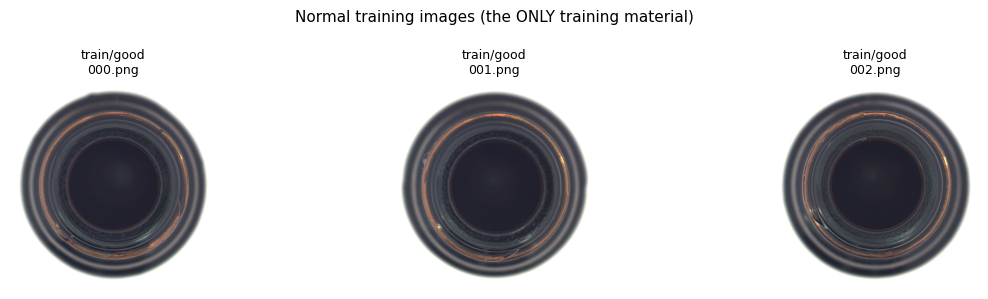

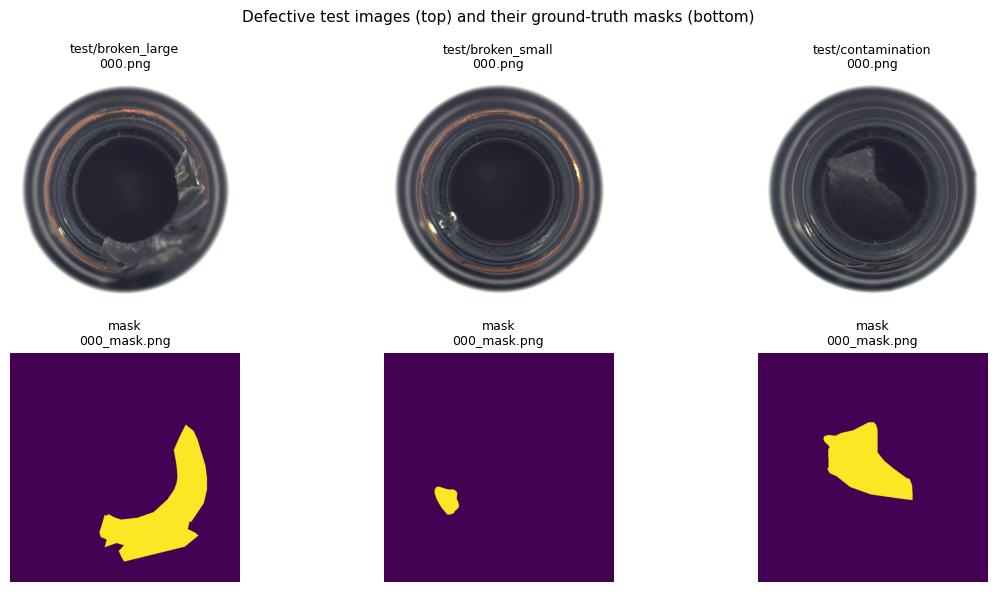

In [8]:
# Visual check: normal training images, then defective test images with their masks
import matplotlib.pyplot as plt
from PIL import Image


def show(path, ax, title):
    ax.imshow(Image.open(path))
    ax.set_title(title, fontsize=9)
    ax.axis("off")


normals = report.train_good[:3]
if normals:
    fig, axes = plt.subplots(1, len(normals), figsize=(4 * len(normals), 3), squeeze=False)
    for ax, path in zip(axes[0], normals):
        show(path, ax, f"train/good\n{path.name}")
    plt.suptitle("Normal training images (the ONLY training material)", fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print("No normal training images to show - see the ERRORS above.")

pairs = []
for name in report.defect_names:
    images = report.test_by_defect[name]
    if not images:
        continue
    img = images[0]
    mask = next(
        (m for m in report.masks_by_defect.get(name, []) if m.stem == img.stem + "_mask"),
        None,
    )
    pairs.append((name, img, mask))
    if len(pairs) == 3:
        break

if pairs:
    fig, axes = plt.subplots(2, len(pairs), figsize=(4 * len(pairs), 6), squeeze=False)
    for col, (name, img, mask) in enumerate(pairs):
        show(img, axes[0][col], f"test/{name}\n{img.name}")
        if mask is None:
            axes[1][col].text(0.5, 0.5, "MASK MISSING", ha="center", va="center", color="red")
            axes[1][col].set_title("ground truth", fontsize=9)
            axes[1][col].axis("off")
        else:
            show(mask, axes[1][col], f"mask\n{mask.name}")
    plt.suptitle("Defective test images (top) and their ground-truth masks (bottom)", fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print("No defective images to display - see the ERRORS above.")

## Final checklist

Every line must read PASS. A FAIL means the dataset is incomplete or damaged -
fix it before building the data pipeline (Stage 3). The last two lines repeat the
split rule that every later stage must keep: training sees only defect-free
`train/good` images; `test/` and `ground_truth/` are for inspection and final
evaluation, never for training or hyperparameter tuning.

In [9]:
# Final checklist: every line must read PASS before Stage 3 (the data pipeline)
def dataset_is_git_safe(path, repo_root):
    """The dataset must live outside the repo, or in a git-ignored folder inside it."""
    try:
        rel = Path(path).resolve().relative_to(Path(repo_root).resolve())
    except ValueError:
        return True  # outside the repository - nothing to commit
    return str(rel).replace("\\", "/").startswith(("data/", "outputs/"))


checks = [
    ("dataset root located", dataset_root.is_dir()),
    ("all 15 categories present", len(layout) == len(CATEGORIES)),
    ("normal training images found", len(report.train_good) > 0),
    ("normal test images found", len(report.test_good) > 0),
    ("defective test images found", report.n_test_defective > 0),
    ("every defective image has a ground-truth mask", not report.missing_masks),
    ("no masks without a matching image", not report.orphan_masks),
    ("every image and mask decodes", not report.unreadable),
    ("mask sizes match their images", not report.size_mismatch),
    ("official split intact (train contains only 'good')",
     not any(u.startswith("train/") for u in report.unexpected)),
    ("dataset is not tracked by git", dataset_is_git_safe(dataset_root, REPO_ROOT)),
]

all_ok = True
for label, ok in checks:
    ok = bool(ok)
    all_ok &= ok
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")

if not all_ok:
    raise AssertionError("Fix the FAIL lines above before moving to the data pipeline (Stage 3).")

print("\nSplit reminder: training and validation use ONLY defect-free train/good images.")
print("test/ images and ground_truth/ masks are for inspection and final evaluation")
print("never for training or hyperparameter tuning.")

[PASS] dataset root located
[PASS] all 15 categories present
[PASS] normal training images found
[PASS] normal test images found
[PASS] defective test images found
[PASS] every defective image has a ground-truth mask
[PASS] no masks without a matching image
[PASS] every image and mask decodes
[PASS] mask sizes match their images
[PASS] official split intact (train contains only 'good')
[PASS] dataset is not tracked by git

Split reminder: training and validation use ONLY defect-free train/good images.
test/ images and ground_truth/ masks are for inspection and final evaluation
never for training or hyperparameter tuning.
